In [1]:
using TensorBinding

In [2]:
using LinearAlgebra
using Plots
using ITensors
using ITensorMPS
using Random

#### Functions to create position basis states

In [3]:
function to_bits(n::Integer, L::Integer)
    """
    Function to convert integer n into its binary representation. `lpad` is used to make ensure string is at of length L by adding '0'
    characters to the left and then each character is converted into an integer using the parse comprehension
    """
    return [parse(Int, c) for c in lpad(string(n; base=2), L, '0')]
end

function basis_state(sites, bits::Vector{Int})
    """
    Function to construct position basis states. Each site index x is encoded by its binary representation, given by the input vector `bits`.
    onehot is an ITensor function that is used to create a tensor where all elements are zero except for a single specified element. For a spin
    1/2 site: onehot(site => 1) looks like [1,0] = |0> and onehot(site => 2), like [0,1] = |1>. The comprehension then creates a vector of 
    single-site tensors, e.g., [|0>, |1>, |1>, |0>, ...] and MPS(...) packages them into an MPS.

    Note: Julia indexing convention starts at 1 rather than 0, which is why we have bits[i] + 1
    """
    return MPS([onehot(sites[i] => bits[i] + 1) for i in eachindex(sites)])
end

basis_state (generic function with 1 method)

#### Creating "Good" Single-Particle States:

Procedure:
1. Find orthonormal states $\{\psi_1, \psi_2 \}$ spanning the near-zero subspace using DMRG.
2. Localize Majorana wavefunctions
3. Enforce self-conjugation of Majoranas: $C\gamma = \gamma$
4. Pair up Majoranas to create fermions

In [4]:
# Two orthonormal states spanning the near-zero doublet of H (penalized DMRG on K = H² + η²).
function doublet(Hmpo, sites; η=1e-2, seed=1234, cutoff=1e-20)
    K = TensorBinding.build_K(Hmpo, sites, 0.0, η; cutoff_K=cutoff)
    sw = (nsweeps=15, maxdim=[10, 20, 50, 100, 150], cutoff=cutoff,
          noise=[1e-6, 1e-7, 1e-8, 0.0], outputlevel=0)
    Random.seed!(seed)
    _, ψ1 = dmrg(K, random_mps(sites; linkdims=10); sw...)
    _, ψ2 = dmrg(K, [ψ1], random_mps(sites; linkdims=10); weight=10.0, sw...)
    ψ1 /= norm(ψ1)
    ψ2 = add2(ψ2, -inner(ψ1, ψ2) * ψ1); ψ2 /= norm(ψ2)
    return ψ1, ψ2
end

# Lowest bulk state (gap check): a third DMRG on K, penalized against the doublet {ψ1, ψ2}, converges to the
# eigenstate with the next-smallest |E|, i.e. the bulk band edge. Since K = H² + η², |E_bulk| = √(⟨K⟩ − η²).
# The penalty weight (10) must exceed E_bulk² + η², which holds for |E_bulk| < 3.
function lowest_bulk(Hmpo, sites, ψ1, ψ2; η=1e-2, seed=1234, cutoff=1e-20)
    K = TensorBinding.build_K(Hmpo, sites, 0.0, η; cutoff_K=cutoff)
    sw = (nsweeps=15, maxdim=[10, 20, 50, 100, 150], cutoff=cutoff,
          noise=[1e-6, 1e-7, 1e-8, 0.0], outputlevel=0)
    Random.seed!(seed)
    _, φ = dmrg(K, [ψ1, ψ2], random_mps(sites; linkdims=10); weight=10.0, sw...)
    φ = add2(φ, -inner(ψ1, φ) * ψ1); φ = add2(φ, -inner(ψ2, φ) * ψ2); φ /= norm(φ)
    return φ, sqrt(max(real(inner(φ', K, φ)) - η^2, 0.0))
end

lowest_bulk (generic function with 1 method)

In [5]:
add2(a, b) = +(a, b; cutoff=1e-16)

# Pair the two Majoranas into one ordinary fermion, f = (γ_L + iγ_R)/2.
# In BdG language the wavefunction of f is ψ_f = (γ_L + iγ_R)/√2 with particle (u) and
# hole (v) components. This requires each γ to be a true Majorana, i.e. its own
# particle-hole conjugate Cγ = γ with C = τ_x K (complex conjugate, then swap particle/hole).
# DMRG and the X diagonalization leave each γ with an arbitrary phase: if Cγ = e^{iθ}γ,
# multiplying by e^{iθ/2} makes it exactly self-conjugate. 
function fermion_mode(Hmpo, sites, L; η=1e-2, seed=1234, cutoff=1e-20, gap_factor=nothing)
    """
    Function to pair two Majoranas into one ordinary fermion: ψ = (γ_L + iγ_R)/2. This requires each γ to be localized 
    and a true Majorana, i.e., Cγ = γ where C = τ_x K (complex conjugate, then swap particle/hole). 

    γ are localized by diagonalizing the position matrix X in the near-zero energy subspace spanned by {ψ1, ψ2}, which are found
    using DMRG. 

    
    """
    ψ1, ψ2 = doublet(Hmpo, sites; η=η, seed=seed, cutoff=cutoff)
    nk(k) = ITensor([0.0 0.0; 0.0 1.0], sites[k+1]', sites[k+1])
    on_site(op, ψ, j) = (φ = copy(ψ); φ[j] = noprime(op * φ[j]); φ)
    ψs = (ψ1, ψ2)
    #localize 
    S = [inner(a, b) for a in ψs, b in ψs]
    X = S +
        sum(2.0^(L - k) * [inner(a, on_site(nk(k), b, k + 1)) for a in ψs, b in ψs] for k in 1:L)
    #solve generalized eigenvalue proble
    F = eigen(Hermitian((X + X') / 2), Hermitian((S + S')/2))
    #enforce Cγ = γ
    τx_s = ITensor([0.0 1.0; 1.0 0.0], sites[1]', sites[1]) #Nambu is first index
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx_s * φ[1]); φ)
    fix(γ) = exp(im * angle(inner(γ, C(γ))) / 2) * γ
    γL = fix(add2(F.vectors[1, 1] * ψ1, F.vectors[2, 1] * ψ2))
    γR = fix(add2(F.vectors[1, 2] * ψ1, F.vectors[2, 2] * ψ2))
    ψ = add2(γL, im * γR)
    ψ /= norm(ψ) #normalize before computing E; ‖γL + iγR‖² = 2, so the unnormalized ψ gives 2E
    #find energy
    E = real(inner(ψ', Hmpo, ψ))
    # |1⟩ = the +E state convention
    E < 0 && (ψ = C(ψ); E = -E)
    #gap check (only if gap_factor is given): the doublet must sit well below the bulk, |E_bulk| > gap_factor·E
    E_bulk = NaN
    if gap_factor !== nothing
        _, E_bulk = lowest_bulk(Hmpo, sites, ψ1, ψ2; η=η, seed=seed, cutoff=cutoff)
        E_bulk < gap_factor * E && @warn "gap check failed: |E_bulk| = $E_bulk < $gap_factor × E_mode = $(gap_factor * E)"
    end
    return ψ, E, γL, γR, E_bulk
end

fermion_mode (generic function with 1 method)

In [6]:
# L = 6 
# N = 2^L #total number of sites
# H0 = TensorBinding.get_Hamiltonian("chain_1d", 1.0; L = L) 
# TensorBinding.add_onsite!(H0, _ -> -1.0) 
# TensorBinding.add_superconductivity!(H0, 1.0) 

In [7]:
Lℓ = 6
Nℓ = 2^Lℓ #2^L lattice sites 
V_in, V_out = -1.0, -4.0 #topological and trival values of chemical potential
region(ℓ) = ((Nℓ - ℓ) ÷ 2 + 1):((Nℓ - ℓ) ÷ 2 + ℓ)  #site dependent potential; 1-indexed sites, centered; for given l gives a centered region
ℓ = 1
reg = region(ℓ)
Vf(n) = (n + 1) in reg ? V_in : V_out                  # add_onsite! passes a 0-indexed site; if in centered region set chemical potential to topological value, else trivial
H0 = TensorBinding.get_Hamiltonian("chain_1d", 1.0; L = Lℓ) #initialize Hamiltonian
TensorBinding.add_onsite!(H0, Vf) #add chemical potential
TensorBinding.add_superconductivity!(H0, 1.0) #add sc

[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.


TBHamiltonian | L=6, N=64 +BdG, scale=auto, maxlinkdim=5 | geometry: 64 sites, 1D | no Tn cache

In [8]:
psi, E, γL, γR = fermion_mode(H0.mpo, H0.sites, Lℓ);

In [9]:
site_weights(γ) = [sum(abs2(inner(basis_state(H0.sites, vcat([nb], to_bits(x - 1, H0.L))), γ)) for nb in 0:1) #nb = Nambu index, 0 = 
                   for x in 1:H0.N];
#spatial profiles of left and right MZMs
wL, wR = site_weights(γL), site_weights(γR);
psi_weights = site_weights(psi);
τx_s = ITensor([0.0 1.0; 1.0 0.0], H0.sites[1]', H0.sites[1]); #Nambu is first index
C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx_s * φ[1]); φ);
psibar = C(psi)
psibar_weights = site_weights(psibar);

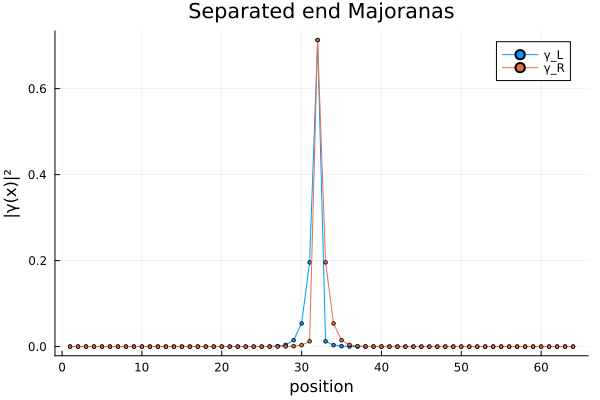

In [10]:
plot(1:H0.N, max.(wL, 1e-30); label="γ_L", marker=:circle, markersize=2,
     xlabel="position", ylabel="|γ(x)|²", title="Separated end Majoranas")
plot!(1:H0.N, max.(wR, 1e-30); label="γ_R", marker=:circle, markersize=2)

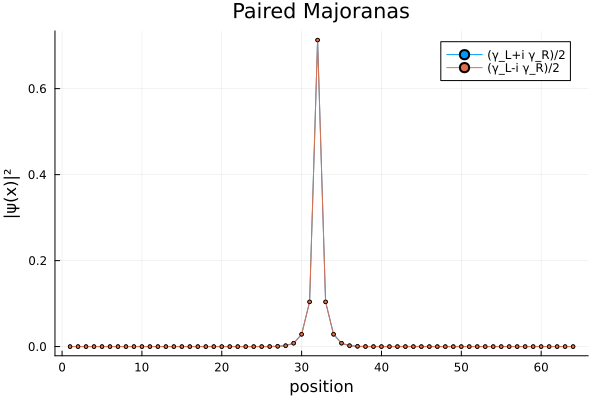

In [11]:
plot(1:H0.N, max.(psi_weights, 1e-30); marker=:circle, markersize=2,label="(γ_L+i γ_R)/2",
     xlabel="position", ylabel="|ψ(x)|²", title="Paired Majoranas")
plot!(1:H0.N, max.(psibar_weights, 1e-30); marker=:circle, markersize=2,label="(γ_L-i γ_R)/2",
     xlabel="position", ylabel="|ψ(x)|²", title="Paired Majoranas")

┌ Info: KPM_Tn: spectral bounds estimated by DMRG
│   E_min = -5.990002019661027
│   E_max = 5.990225124984042
│   center = 0.0001115526615076412
└   scale = 6.58912492955479
[ Info: H.nambu_s detected; auto-enabling nambu_proj=true (pass proj_nambu=1/2 to select particle/hole sector).


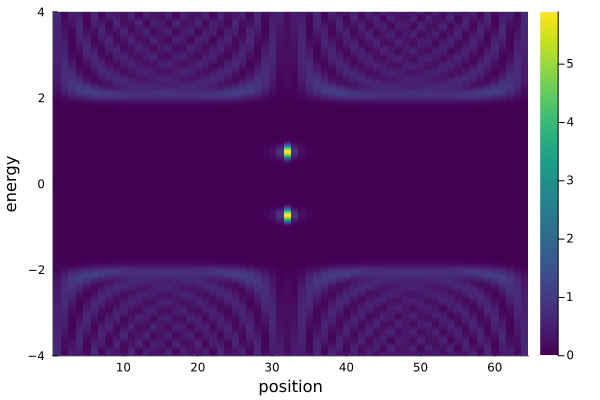

In [12]:
Ncheb = 200
mdim = 60 #bond dimension
omega = range(-4.0, 4.0; length=1500)
num_x = H0.N

ldos = TensorBinding.get_ldos_spatial(H0, Ncheb, collect(omega); num_x=num_x, mode=:mpo, maxdim=mdim, verbose=false);

heatmap(1:num_x, collect(omega), ldos; xlabel="position", ylabel="energy",colorbar=true,c=:viridis)

In [13]:
# Bulk gap edge E_gap from the KPM LDOS. DOS(ω) = Σ_x A(x, ω), averaged over ±ω (BdG symmetry). Points within
# mode_width of E_mode (≈ 3× the KPM resolution π·scale/Ncheb ≈ 0.1) are skipped so the mode's own peak is not taken
# for the band edge. E_gap is the half-maximum point on the rising flank of the first DOS peak above that; the
# peak itself sits ~0.1 above the true edge because of the KPM broadening.
function kpm_gap(ldos, omega, E_mode; mode_width=0.3)
    ω = collect(omega)
    dos = vec(sum(ldos; dims=2))
    D(w) = (dos[argmin(abs.(ω .- w))] + dos[argmin(abs.(ω .+ w))]) / 2
    ws = ω[ω .> abs(E_mode) + mode_width]
    Ds = D.(ws)
    noise = 0.1 * maximum(Ds)
    j = findfirst(k -> Ds[k] > noise && Ds[k] >= Ds[k+1], 1:length(Ds)-1)     # first bulk peak
    half = Ds[j] / 2
    i = findlast(k -> Ds[k] < half, 1:j)                                       # rising flank
    return ws[i] + (half - Ds[i]) * (ws[i+1] - ws[i]) / (Ds[i+1] - Ds[i])
end


kpm_gap (generic function with 1 method)

### How states are built:
Routine constructs and compares two qubit states associated with a (nearly) zero-energy fermionic mode in a superconducting (BdG) system.

- |0>: fermionic mode is empty
- |1>: fermionic mode is occupied

Instead of representing the many-body states explicitly, the code used their BdG correlation matrices
$$
    \Gamma_{ab} = \langle \Psi^{\dagger}_{b} \Psi_{a} \rangle, \; \; \Psi = (c_1, ..., c_N, c_1^{\dagger}, ..., c_N^{\dagger} )
$$

Because the Hamiltonian is quadratic, $\Gamma$ completely characterizes the BCS state. The correlation matrix $\Gamma$ is the projector onto its occupied BdG states and is an MPO here. 

Steps:
1. Construct the bulk projector: Both $|0\rangle$ and $|1\rangle$ share the same filled bulk and only differ in which near zero state ($-\varepsilon$ or $+\varepsilon$) is filled. The Fermi level, `ϵF` is chosen to (1) lie above all negative-energy bulk states and (2) lie below ($-\varepsilon$, $+\varepsilon$). McWeeny purification produces $\rho_{\text{bulk}} = P_{\text{bulk}} = \sum_{\text{bulk } E_n < 0} |\psi_n\rangle \langle \psi_n |$.

2. Build logical states: 
- $|0\rangle$ (mode empty): $\Gamma_0 = P_{\text{bulk}} + |\bar{\psi}_f \rangle \langle \bar{\psi}_f |$
- $|1 \rangle$ (mode occupied): $\Gamma_1 = P_{\text{bulk}} + |\psi_f \rangle \langle \psi_f |$

Settings: Accuracy needs `cutoff=1e-20` and `tol=1e-8`. With looser settings, or by iterating past convergence, $P_{\text{bulk}}$ drifts to about $10^{-5}$ error; McWeeny doesn't correct errors that mix occupied and empty states, so they build up. 

E_mode = 0.7379126518699902,  E_gap (KPM) = 1.9519546763667408  →  ϵF = -(E_mode + E_gap)/2 = -1.3449336641183656
Tr P_bulk = 63.00000000033258  (N - 1 = 63)
mode occupation ⟨d†d⟩ = ⟨ψ|Γ|ψ⟩:  |0⟩ → -2.5512057493169154e-14,  |1⟩ → 0.9999999999999721
mode occupation ⟨d†d⟩ = ⟨ψbar|Γ|ψbar⟩:  |0⟩ → 1.0000000003442107,  |1⟩ → 3.4420697215025827e-10
E1 - E0 = 0.7379126453782021  (should equal the mode energy E = 0.7379126518699902 from fermion_mode; small only when the MZMs are far apart)


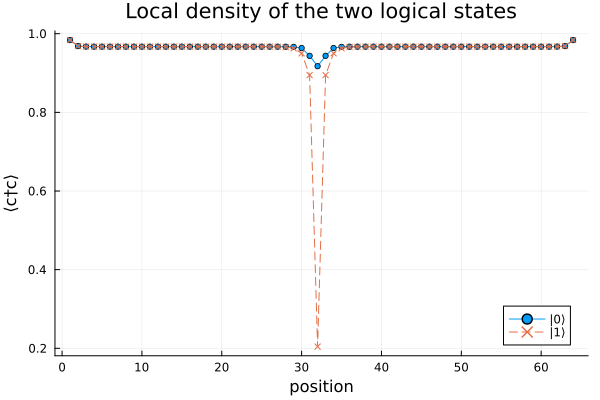

In [14]:
#contains all bulk quasiparticle states but neither of the zero-energy modes
#ϵF sits in the gap between the fermion mode and the bulk: ϵF = -(E_mode + E_gap)/2, with E_mode = E from
#fermion_mode (cell above) and E_gap from the KPM LDOS. McWeeny fills every state below ϵF, i.e. all
#negative-energy bulk quasiparticle states but neither member (±E_mode) of the fermion mode
E_gap = kpm_gap(ldos, omega, E)
ϵF = -(E + E_gap) / 2
println("E_mode = ", E, ",  E_gap (KPM) = ", E_gap, "  →  ϵF = -(E_mode + E_gap)/2 = ", ϵF)
ρ_bulk = TensorBinding.mcweeny_purify(H0; ϵF=ϵF, maxiters=60, maxdim=200,
                                      cutoff=1e-20, tol=1e-8)

#define particle-hole conjugation; Pauli-X acting in Nambu space
τx = ITensor([0.0 1.0; 1.0 0.0], H0.sites[1]', H0.sites[1]) 
#implements C on ψ; dag(ψ) = complex conj, τx * φ[1] = swaps p and h indices
Cop(ψ) = (φ = dag(ψ); φ[1] = noprime(τx * φ[1]); φ)
psi_bar = Cop(psi)
#construct |0> and |1>
Γ0 = +(ρ_bulk, outer(psi_bar', psi_bar); cutoff=1e-20)
Γ1 = +(ρ_bulk, outer(psi', psi); cutoff=1e-20)

#verify bulk sector: Tr(P) = rank(P) for projector; Tr(P_bulk) = N - 1 
println("Tr P_bulk = ", real(tr(ρ_bulk)), "  (N - 1 = ", H0.N - 1, ")")

#verify occupation of |0> and |1>
println("mode occupation ⟨d†d⟩ = ⟨ψ|Γ|ψ⟩:  |0⟩ → ", real(inner(psi', Γ0, psi)),
        ",  |1⟩ → ", real(inner(psi', Γ1, psi)))
println("mode occupation ⟨d†d⟩ = ⟨ψbar|Γ|ψbar⟩:  |0⟩ → ", real(inner(psi_bar', Γ0, psi_bar)),
        ",  |1⟩ → ", real(inner(psi_bar', Γ1, psi_bar)))

# many-body energy of a BCS state: ½ Tr(H Γ) (up to a constant); inner(A, B) = Tr(A†B), exact
E0 = real(inner(H0.mpo, Γ0)) / 2 #inner = trace
E1 = real(inner(H0.mpo, Γ1)) / 2
println("E1 - E0 = ", E1 - E0, "  (should equal the mode energy E = ", E, " from fermion_mode; small only when the MZMs are far apart)")

# Local density n(x) = ⟨c_x† c_x⟩ = particle-particle diagonal of Γ.
#pbasis(x) = single-particle basis state localized at site x; creates BdG vector corresponding to c_x
pbasis(x) = basis_state(H0.sites, vcat([0], to_bits(x - 1, H0.L))) #leading zero selects particle sector 
n0 = [real(inner(pbasis(x)', Γ0, pbasis(x))) for x in 1:H0.N]
n1 = [real(inner(pbasis(x)', Γ1, pbasis(x))) for x in 1:H0.N]
# Γ1 - Γ0 = |ψf⟩⟨ψf| - |ψfbar⟩⟨ψfbar| exactly, so compute the difference without
# subtracting two purified MPOs: δn(x) = |u_f(x)|² - |u_fbar(x)|² = |u(x)|² - |v(x)|².

p1 = plot(1:H0.N, n0; label="|0⟩", marker=:circle, markersize=3, xlabel="position",
          ylabel="⟨c†c⟩", title="Local density of the two logical states")
plot!(p1, 1:H0.N, n1; label="|1⟩", marker=:x, markersize=3, linestyle=:dash)

#### Charge difference versus length of topological region

In [15]:
# ΔQ between |0⟩ and |1⟩ as the two MZMs are brought together.
# One topological region (μ = -1) of length ℓ, centered in the 64-site chain, trivial (μ = -4)
# elsewhere. The MZMs sit at the two ends of the region, so shrinking ℓ pushes them together.
# For each ℓ: zero-mode pair from penalized DMRG on K → gap check (third DMRG for the lowest bulk state) → localize with X̂ → make each γ
# self-conjugate → pair into ψ_f → keep the +E member (|1⟩) → ΔQ = ⟨ψ_f|τ_z|ψ_f⟩.
Lℓ = 6
Nℓ = 2^Lℓ #2^L lattice sites 
V_in, V_out = -1.0, -4.0 #topological and trival values of chemical potential
region(ℓ) = ((Nℓ - ℓ) ÷ 2 + 1):((Nℓ - ℓ) ÷ 2 + ℓ)  #site dependent potential; 1-indexed sites, centered; for given l gives a centered region

#Pauli-Z
τz_on(ψ, s) = (φ = copy(ψ); φ[1] = noprime(ITensor([1.0 0.0; 0.0 -1.0], s[1]', s[1]) * φ[1]); φ)
#ΔQ = ⟨ψ_f|τ_z|ψ_f⟩
ΔQ_mode(ψ, s) = real(inner(ψ, τz_on(ψ, s)))

ΔQ_mode (generic function with 1 method)

In [16]:
function charge_difference(ℓ; η=1e-2, seed=1234, cutoff=1e-20, gap_factor=2.0)
    #build Hamiltonian
    reg = region(ℓ)
    Vf(n) = (n + 1) in reg ? V_in : V_out                  # add_onsite! passes a 0-indexed site; if in centered region set chemical potential to topological value, else trivial
    H = TensorBinding.get_Hamiltonian("chain_1d", 1.0; L = Lℓ) #initialize Hamiltonian
    TensorBinding.add_onsite!(H, Vf) #add chemical potential
    TensorBinding.add_superconductivity!(H, 1.0) #add sc
    s = H.sites
    pb(x) = basis_state(s, vcat([0], to_bits(x - 1, Lℓ))) #site basis states
    onsite_err = maximum(abs(real(inner(pb(x)', H.mpo, pb(x))) - Vf(x - 1)) for x in 1:Nℓ)
    onsite_err > 1e-6 && @warn "ℓ = $ℓ: on-site potential of H deviates from Vf by $onsite_err"

    #call fermion_mode to construct psi
    psi, E, γL, γR, E_bulk = fermion_mode(H.mpo, s, Lℓ; η=η, seed=seed, cutoff=cutoff, gap_factor=gap_factor)

    return (ΔQ = ΔQ_mode(psi, s), E = E, E_bulk = E_bulk) #ΔQ = ⟨ψ_f|τ_z|ψ_f⟩, psi is +E member (|1⟩) by the convention chosen fermion_mode
end

charge_difference (generic function with 1 method)

In [17]:
ℓs = 1:40
sweep_ℓ = [charge_difference(ℓ) for ℓ in ℓs]

[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi

40-element Vector{@NamedTuple{ΔQ::Float64, E::Float64, E_bulk::Float64}}:
 (ΔQ = -0.8480572282027019, E = 0.7379126518699902, E_bulk = 2.0181116647589175)
 (ΔQ = -0.6107229591901078, E = 0.3220491639437889, E_bulk = 2.0181460202942985)
 (ΔQ = -0.4209183627822821, E = 0.1536027651622528, E_bulk = 1.789094661624525)
 (ΔQ = -0.2765570542221763, E = 0.07557417267261798, E_bulk = 1.5330163390807487)
 (ΔQ = -0.17377015986182423, E = 0.037588442417957446, E_bulk = 1.375267190014902)
 (ΔQ = -0.10522915502426179, E = 0.01876320805074341, E_bulk = 1.2745596857602741)
 (ΔQ = -0.06191415570687102, E = 0.009376923638787615, E_bulk = 1.2076768784447323)
 (ΔQ = -0.035631418340916474, E = 0.004687774700058647, E_bulk = 1.1616129289414832)
 (ΔQ = -0.020157268741473888, E = 0.0023437886254581465, E_bulk = 1.1288387914107652)
 (ΔQ = -0.011250157624820848, E = 0.0011718803644811793, E_bulk = 1.1048408815607178)
 (ΔQ = -0.006210961394155813, E = 0.0005859382376099729, E_bulk = 1.086820653363299)
 (ΔQ = -0.

In [18]:
ΔQ_ℓ, E_ℓ = [r.ΔQ for r in sweep_ℓ], [r.E for r in sweep_ℓ];

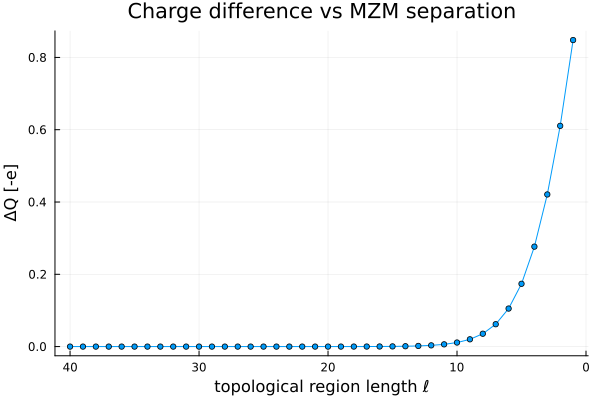

In [19]:
p1 = plot(ℓs, abs.(ΔQ_ℓ); marker=:circle, markersize=3,
          xlabel="topological region length ℓ", ylabel="ΔQ [-e]", label="",
          title="Charge difference vs MZM separation", xflip=true)

In [20]:
#calculate charge diffence using projectors Γ0 and Γ1
function charge_difference_method_2(ℓ; η=1e-2, seed=1234, cutoff=1e-20, gap_factor=2.0)
    #build Hamiltonian
    reg = region(ℓ)
    Vf(n) = (n + 1) in reg ? V_in : V_out  # add_onsite! passes a 0-indexed site; if in centered region set chemical potential to topological value, else trivial
    H = TensorBinding.get_Hamiltonian("chain_1d", 1.0; L = Lℓ) #initialize Hamiltonian
    TensorBinding.add_onsite!(H, Vf) #add chemical potential
    TensorBinding.add_superconductivity!(H, 1.0) #add sc
    s = H.sites
    pb(x) = basis_state(s, vcat([0], to_bits(x - 1, Lℓ))) #site basis states
    onsite_err = maximum(abs(real(inner(pb(x)', H.mpo, pb(x))) - Vf(x - 1)) for x in 1:Nℓ)
    onsite_err > 1e-6 && @warn "ℓ = $ℓ: on-site potential of H deviates from Vf by $onsite_err"

    #call fermion_mode to construct psi
    psi, E, γL, γR, E_bulk = fermion_mode(H.mpo, s, Lℓ; η=η, seed=seed, cutoff=cutoff, gap_factor=gap_factor)

    τx_s = ITensor([0.0 1.0; 1.0 0.0], s[1]', s[1])
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx_s * φ[1]); φ)
    psibar = C(psi)
    
    upart(ψ) = [abs2(inner(pb(x),ψ)) for x in 1:H.N]
    n_density = upart(psi) - upart(psibar)
    charge_diff = sum(n_density) 
    return charge_diff
end

charge_difference_method_2 (generic function with 1 method)

In [21]:
ℓs = 1:40
δn_ℓ_alt = [charge_difference_method_2(ℓ) for ℓ in ℓs];

[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.
[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi

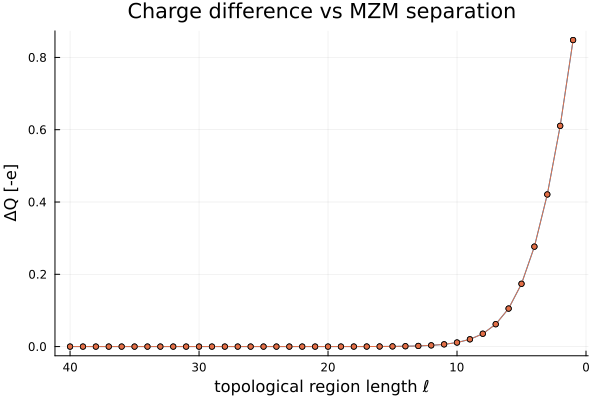

In [22]:
plot(ℓs, abs.(ΔQ_ℓ); marker=:circle, markersize=3,
          xlabel="topological region length ℓ", ylabel="ΔQ [-e]", label="",
          title="Charge difference vs MZM separation", xflip = true)
plot!(ℓs, abs.(δn_ℓ_alt); marker=:circle, markersize=3,
          xlabel="topological region length ℓ", ylabel="ΔQ [-e]", label="",
          title="Charge difference vs MZM separation", xflip = true)

### Time-dependent calculation

At $t = 0$ the 32-site chain ($L_t = 5$) is topological ($\mu_{\text{topo}} = -0.4$) with MZMs at its ends. The sites are then ramped to the trivial value $\mu_{\text{triv}} = -5.6$ from the chain ends inward, each with a small delay, which carries the MZMs toward the middle. At $t = T$ only the center site ($\ell_{\text{center}} = 1$, $x = 16$) is still topological, so the two MZMs overlap and the logical states differ in charge.

$$\mu(x,t) = \mu_{\text{topo}} + (\mu_{\text{triv}} - \mu_{\text{topo}})\, s\big(q_i(t)\big),\qquad q_i(t) = \frac{t}{T}\big[1 + \alpha(N_{\text{leg}} - 1)\big] - \alpha i,\qquad s(\tau) = 3\tau^2 - 2\tau^3$$

where $i$ is the distance of site $x$ from the nearest chain end, $\alpha = 0.025$, and $s$ is clamped to $[0, 1]$. The $N_t - \ell_{\text{center}} = 31$ ramped sites
cannot split evenly: the left leg has 15 sites ($x = 1 \dots 15$) and the right leg 16 ($x = 17 \dots 32$). $N_{\text{leg}} = 16$ is the longer leg.

- **Site-delayed ramp:** site $i$ starts at $t = \alpha i\,T / [1 + \alpha(N_{\text{leg}} - 1)]$ and every site ramps over the same duration $T / [1 + \alpha(N_{\text{leg}} - 1)]$. The outermost sites go first and the trivial region grows inward from both ends at the same rate. The innermost site of the longer
  (right) leg finishes at $t = T$, that of the shorter (left) leg at $t/T = (1 + 14\alpha)/(1 + 15\alpha) \approx 0.98$.
- **Why not a uniform ramp:** ramping $\mu$ everywhere at once crosses $|\mu| = 2t$ in the whole chain together and closes the bulk gap. With the delay, the instantaneous bulk gap stays $\geq 0.83$ for the whole ramp (minimum at $t/T \approx 0.43$; see the Fermi-level scan below).
- **Smooth in time:** every site follows the smoothstep $s(\tau) = 3\tau^2 - 2\tau^3$, which starts and stops with zero velocity.

**What is evolved.** $\Gamma_1(t) - \Gamma_0(t) = |\psi_f\rangle\langle\psi_f| - |C\psi_f\rangle\langle C\psi_f|$ at all times (the shared bulk cancels), so the charge difference $\Delta Q(t) = \langle\psi_f(t)|\tau_z|\psi_f(t)\rangle$ needs only the single BdG vector $\psi_f$, evolved with $i\partial_t\psi = H(t)\psi$ by TDVP. At $t = T$, the weight of $\psi_f$ outside the instantaneous $\pm E$ doublet is the leakage into bulk quasiparticles: the non-adiabatic error. The full densities $n_0(x,t)$, $n_1(x,t)$ at the end of the section add the shared bulk, either evolved by TDVP (all $N_t - 1$ filled states) or taken adiabatically from McWeeny purification of $H(t)$.

In [23]:
# Initial fermion mode, time evolution, and end-of-ramp analysis.
# These work for any chain length: sites and L are passed explicitly, and doublet/add2 come from
# the cells near the top, so nothing here reads the globals st or Lt.

# Particle-hole conjugation C = τ_x K; τ_x acts on the Nambu index, read off ψ's own first site.
C_t(ψ) = (φ = dag(ψ); s = siteind(φ, 1); φ[1] = noprime(ITensor([0.0 1.0; 1.0 0.0], s', s) * φ[1]); φ)

# Initial fermion mode: localize the doublet with X̂, make each γ self-conjugate, pair them.
function initial_mode(Hmpo, sites, L)
    ψ1, ψ2 = doublet(Hmpo, sites)
    nk(k) = ITensor([0.0 0.0; 0.0 1.0], sites[k+1]', sites[k+1])
    on_site(op, ψ, j) = (φ = copy(ψ); φ[j] = noprime(op * φ[j]); φ)
    ψs = (ψ1, ψ2)
    X = [inner(a, b) for a in ψs, b in ψs] +
        sum(2.0^(L - k) * [inner(a, on_site(nk(k), b, k + 1)) for a in ψs, b in ψs] for k in 1:L)
    F = eigen(Hermitian((X + X') / 2))
    fix(γ) = exp(im * angle(inner(γ, C_t(γ))) / 2) * γ
    γL = fix(add2(F.vectors[1, 1] * ψ1, F.vectors[2, 1] * ψ2))
    γR = fix(add2(F.vectors[1, 2] * ψ1, F.vectors[2, 2] * ψ2))
    ψ = add2(γL, im * γR)
    return ψ / norm(ψ)
end

# Instantaneous ±E eigenstates at the end of the ramp (E is large there, so H separates them).
function final_branches(Hmpo, sites)
    ψ1, ψ2 = doublet(Hmpo, sites) #low energy doublet
    ψs = (ψ1, ψ2) #pack into tuple for convenience 
    Hm = [inner(a', Hmpo, b) for a in ψs, b in ψs] #build H in the low energy subspace
    F = eigen(Hermitian((Hm + Hm') / 2)) #diagonalize
    mk(c) = add2(c[1] * ψ1, c[2] * ψ2) #convert coefficient vector to many-body statef
    return mk(F.vectors[:, 2]), mk(F.vectors[:, 1]), F.values[2]    # ψ₊, ψ₋, E₊
end

final_branches (generic function with 1 method)

In [24]:
Lt = 5
Nt = 2^Lt
μ_topo_t, μ_triv_t = -0.4, -5.6

smoothstep(τ) = τ <= 0 ? 0.0 : τ >= 1 ? 1.0 : τ^2 * (3 - 2τ)

alpha = 0.025 #delay coefficient
ℓ_center = 1                              # sites kept topological in the middle
N_left  = (Nt - ℓ_center) ÷ 2             # 15 ramped sites on the left  (x = 1 … 15)
N_right = Nt - ℓ_center - N_left          # 16 ramped sites on the right (x = 17 … 32): 31 sites cannot split evenly
N_leg   = max(N_left, N_right)            # 16: the innermost ramped site of the longer leg (i = 15) finishes at t = T

# Site-delayed ramp; i = distance from the nearer chain end, so the outermost sites ramp first and the walls
# move inward at the same rate on both sides. Site i starts at t = T·αi/(1 + α(N_leg−1)) and every site ramps for
# the same duration T/(1 + α(N_leg−1)). Works for odd and even ℓ_center.
function mu_xt(x, t, T, ramp; α = alpha)
    (x <= N_left || x > Nt - N_right) || return μ_topo_t
    i = min(x - 1, Nt - x)
    q = (t/T) * (1 + α * (N_leg - 1)) - α * i
    return μ_topo_t + (μ_triv_t - μ_topo_t) * ramp(q)
end

# H(t) = H_static + τ_z ⊗ diag(μ(x,t)). The hopping + pairing part is built once. The onsite part
# is built exactly from its N values (MPS from the dense 2×…×2 array, then a diagonal MPO), which
# avoids rebuilding the whole Hamiltonian (and running QTCI) at every time step.
H_static = TensorBinding.get_Hamiltonian("chain_1d", 1.0; L = Lt)
TensorBinding.add_superconductivity!(H_static, 1.0)
st = H_static.sites
nambu_t, pos_t = st[1], st[2:end]

function onsite_mpo(V)
    arr = zeros(ntuple(_ -> 2, Lt)...) #creates 2 x 2 x 2 x 2 x 2 x 2 tensor
    for I in CartesianIndices(arr) #decode binary position
        b = Tuple(I) .- 1   # position bits, most significant first
        #fill tensor with onsite energies; V(x) = mu_xt(x, t, T, ramp); tensor arr stores the chemical potential at every position
        arr[I] = V(1 + sum(b[k] * 2^(Lt - k) for k in 1:Lt)) #x = 1 + sum_k b_k * 2^(Lt - k); converts bit string into the site index
    end
    #convert to diagonal MPO; dense tensor -> MPS compression -> diagonal MPO
    D = TensorBinding.mps_to_diagonal_mpo(MPS(arr, pos_t; cutoff=1e-16), pos_t)
    return TensorBinding.prepend_nambu(D, nambu_t, :tz) #add nambu structure
end

#time-dependent Hamiltonian
H_of_t_alt(t, T, ramp) = +(H_static.mpo, onsite_mpo(x -> mu_xt(x, t, T, ramp)); cutoff=1e-16)

pbt(x) = basis_state(st, vcat([0], to_bits(x - 1, Lt))) #basis state |particle> |x> (leading 0 selects particle sector; remaining bits encode the position)
for tchk in (0.0, 40.0, 80.0)
    Hchk = H_of_t_alt(tchk, 80.0, smoothstep)
    err = maximum(abs(real(inner(pbt(x)', Hchk, pbt(x))) - mu_xt(x, tchk, 80.0, smoothstep)) for x in 1:Nt)
    println("t = $tchk (T = 80): max onsite error = $err,  maxlinkdim(H) = $(maxlinkdim(Hchk))")
end

t = 0.0 (T = 80): max onsite error = 1.7763568394002505e-15,  maxlinkdim(H) = 5


[ Info: On-site (s-wave) pairing is forbidden for spinless fermions (Δ(i,i) = 0 by Fermi antisymmetry).  Constructing nearest-neighbour p-wave instead.


t = 40.0 (T = 80): max onsite error = 3.419486915845482e-14,  maxlinkdim(H) = 8
t = 80.0 (T = 80): max onsite error = 1.0658141036401503e-14,  maxlinkdim(H) = 6


In [25]:
ψf_init = initial_mode(H_of_t_alt(0.0, 1.0, smoothstep), st, Lt)     # H(0) is the same for every T and ramp
norm_Hψ(H, ψ) = norm(orthogonalize(apply(H, ψ; alg="naive", truncate=false), 1)[1])
println("initial mode: ‖Hψ‖ = ", norm_Hψ(H_of_t_alt(0.0, 1.0, smoothstep), ψf_init),
        ",  ΔQ(0) = ", ΔQ_mode(ψf_init, st))

initial mode: ‖Hψ‖ = 1.1242403249790992e-12,  ΔQ(0) = 4.5916966548765526e-15


In [26]:
function run_ramp(T, ramp; dt=0.1, nsnap=100)
    """
    T = total ramp duration
    ramp = ramp function (smoothstep)
    dt = target timestep
    nsnap = number of snapshots to save

    Goal is to solve i d/dt |psi(t)> = H(t) |psi(t)> from t = 0 to t = T
    
    1. Evolve initial Majorana state under H(t)
    2. Project the final state onto the instantaneous low-energy doublet
    3. Measures nonadiabatic errors through leak
    4. Tracks the charge difference during the protocol
    """
    nsteps = round(Int, T / dt) #number of time steps
    dt = T / nsteps #time step adjusted so that n_steps*dt = T

    #TDVP evolution; numerically integrates i d/dt |psi(t)> = H(t) |psi(t)>
    #evolution produces psi(t0), psi(t1), psi(t2), ..., psi(tN) in states
    #reverse_step = true; on-site TDVP sweep normally consists of (1) forward sweep
    #(2) backward sweep through the MPS
    states = TensorBinding.evolve_with_tdvp_timedep(t -> H_of_t_alt(t, T, ramp), ψf_init, nsteps, dt;
                                                    maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30,
                                                    reverse_step=true)
    #construct final instantaneous eigenstates
    ψ₊, ψ₋, E₊ = final_branches(H_of_t_alt(T, T, ramp), st)
    #state produced by the time evolution
    ψT = states[end]
    #overlap with the final doublet
    p₊, p₋ = abs2(inner(ψ₊, ψT)), abs2(inner(ψ₋, ψT))
    #determine which branch was reached
    σ = p₋ > p₊ ? -1 : 1
    σ == -1 && ((p₊, p₋) = (p₋, p₊))
    idx = unique(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    #leak = 1 - (p_minus + p_plus) measures probability transferred into bulk quasiparticle excitations
    return (T = T, leak = 1 - p₊ - p₋, p_wrong = p₋, E₊ = E₊,
            ΔQ_final = σ * ΔQ_mode(ψT, st), ΔQ_adiabatic = ΔQ_mode(ψ₊, st),
            times = (idx .- 1) .* dt, ΔQ_t = [σ * ΔQ_mode(states[i], st) for i in idx],
            snapshots = states[idx])
end

run_ramp (generic function with 1 method)

In [27]:
# Ramp-time scan for the smoothstep ramp (MPS/TDVP): leak and ΔQ(T) as the protocol is slowed down.
Ts_ramp = [150.0, 200.0, 250.0, 300.0, 350.0]
ramps = [("smoothstep", smoothstep, 1.5)]
ramp_runs = Dict{String,Vector{Any}}()
for (name, r, vfac) in ramps
    ramp_runs[name] = [run_ramp(T, r) for T in Ts_ramp]
    for a in ramp_runs[name]
        println(rpad(name, 13), "T = ", lpad(Int(a.T), 3),
                "  leak = ", round(a.leak, sigdigits=4),
                "  wrong-branch weight = ", round(a.p_wrong, sigdigits=2),
                "  ΔQ(T) = ", round(a.ΔQ_final, digits=6),)
    end
end

smoothstep   T = 150  leak = 1.291e-7  wrong-branch weight = 9.0e-18  ΔQ(T) = -0.889103
smoothstep   T = 200  leak = 5.326e-8  wrong-branch weight = 2.2e-21  ΔQ(T) = -0.889106
smoothstep   T = 250  leak = 1.495e-8  wrong-branch weight = 1.2e-21  ΔQ(T) = -0.889105
smoothstep   T = 300  leak = 5.493e-9  wrong-branch weight = 1.2e-22  ΔQ(T) = -0.889103
smoothstep   T = 350  leak = 4.159e-9  wrong-branch weight = 3.0000000000000004e-22  ΔQ(T) = -0.8891


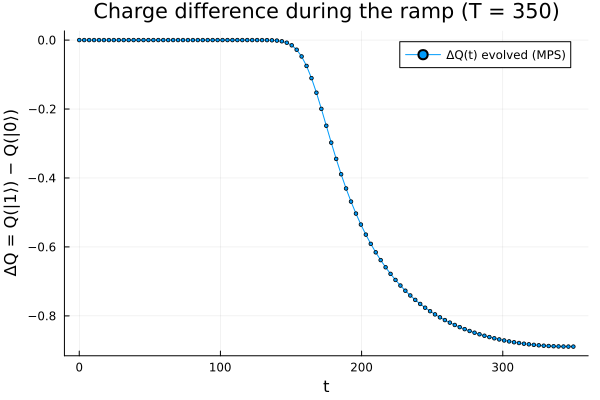

In [28]:
run_show = ramp_runs["smoothstep"][end]
T_show = run_show.T

pQ = plot(run_show.times, run_show.ΔQ_t; marker=:circle, markersize=2, label="ΔQ(t) evolved (MPS)",
          xlabel="t", ylabel="ΔQ = Q(|1⟩) − Q(|0⟩)", title="Charge difference during the ramp (T = $(Int(T_show)))")

In [29]:
# Evolve both logical states and track the difference in their charge densities.
# |0⟩ and |1⟩ share the filled bulk and differ only in which member of the zero-mode pair is filled:
#   Γ₀ = P_bulk + |ψ̄_f⟩⟨ψ̄_f|,   Γ₁ = P_bulk + |ψ_f⟩⟨ψ_f|.
# Both evolve with the same U(t), so Γ₁(t) − Γ₀(t) = |ψ_f(t)⟩⟨ψ_f(t)| − |ψ̄_f(t)⟩⟨ψ̄_f(t)|: the bulk
# cancels exactly. The state-specific parts are the two MPS ψ_f and ψ̄_f, each evolved here by TDVP:
#   δn(x,t) = n₁(x,t) − n₀(x,t) = |u_f(x,t)|² − |u_f̄(x,t)|²     (particle components; charge = −e·δn)
# (Evolving the two full Γ MPOs and subtracting would bury δn, ~1e-14 early on, under truncation error.)
# ψ̄_f is evolved independently rather than taken as Cψ_f, so ‖Cψ_f(t) − ψ̄_f(t)‖ checks the evolution.
function evolve_states(T, ramp; dt=0.1, nsnap=160)
    nsteps = round(Int, T / dt)
    dt = T / nsteps
    ev(ψ0) = TensorBinding.evolve_with_tdvp_timedep(t -> H_of_t_alt(t, T, ramp), ψ0, nsteps, dt;
                                                    maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30,
                                                    reverse_step=true)
    s1, s0 = ev(ψf_init), ev(C_t(ψf_init))
    ψ₊, _, _ = final_branches(H_of_t_alt(T, T, ramp), st)
    abs2(inner(ψ₊, s0[end])) > abs2(inner(ψ₊, s1[end])) && ((s1, s0) = (s0, s1))   # |1⟩: mode ends in +E
    idx = unique(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    upart(ψ) = [abs2(inner(pbt(x), ψ)) for x in 1:Nt]                        # |u(x)|²
    δn = reduce(hcat, [upart(s1[i]) .- upart(s0[i]) for i in idx])            # Nt × n_snapshots
    return (T = T, times = (idx .- 1) .* dt, δn = δn,
            C_err = norm(add2(C_t(s1[end]), -1 * s0[end])),
            n_mode = (abs2(inner(ψ₊, s1[end])), abs2(inner(ψ₊, s0[end]))))
end

charge_runs = [evolve_states(T, smoothstep) for T in (300.0, 100.0)];

# δn(x,t) = n₁(x,t) − n₀(x,t) for a slow (T = 300) and a fast (T = 100) smoothstep ramp.
rows = Any[]
for r in charge_runs
    lim = maximum(abs, r.δn)
    p_lin = heatmap(r.times, 1:Nt, r.δn; c=:RdBu, clims=(-lim, lim), xlabel="t", ylabel="position",
                    colorbar_title="δn", title="n₁ − n₀,  T = $(Int(r.T))")
    push!(rows, p_lin)
end

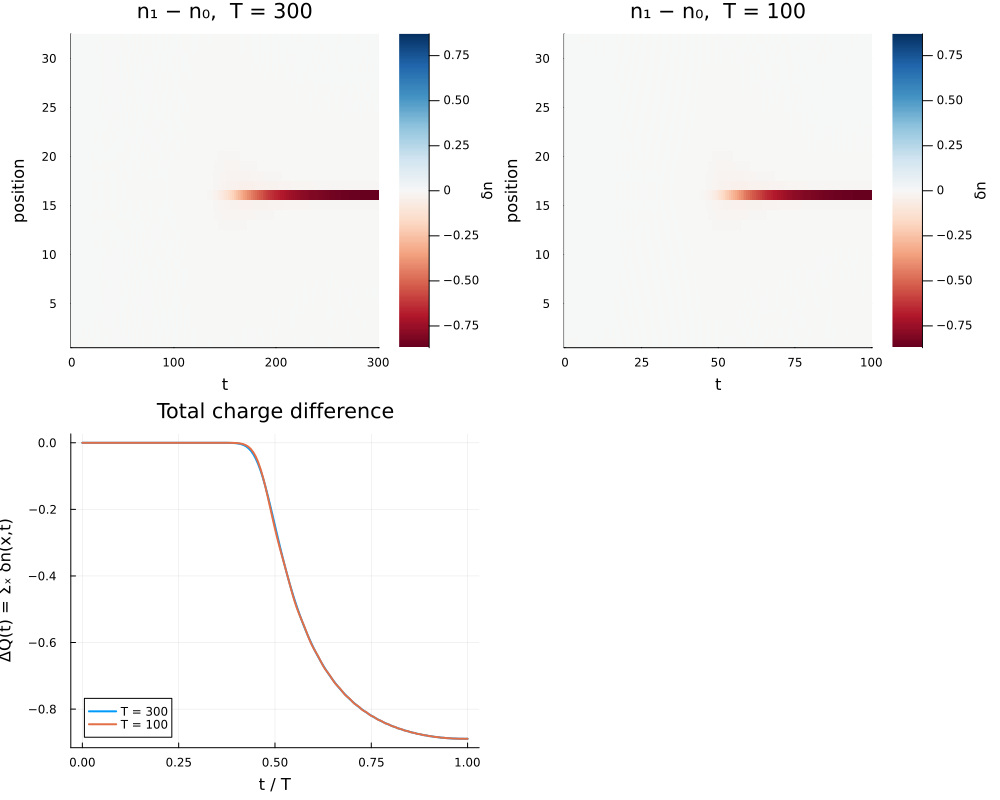

In [30]:
pΔQ = plot(xlabel="t / T", ylabel="ΔQ(t) = Σₓ δn(x,t)", title="Total charge difference", legend=:bottomleft)
for r in charge_runs
    plot!(pΔQ, r.times ./ r.T, vec(sum(r.δn; dims=1)); lw=2, label="T = $(Int(r.T))")
end
plot(rows..., pΔQ; layout=@layout([a b; c d]), size=(1000, 800))

In [31]:
# Bulk filled states at t = 0: the negative-energy eigenstates of H(0) other than the near-zero doublet
# (Nt − 1 of them). For Nt = 32 the BdG matrix is only 2Nt × 2Nt, so they come from exact
# diagonalization of H(0) and are converted to MPS; each is then evolved by TDVP exactly like ψ_f.
bdg_basis = [basis_state(st, vcat([nb], to_bits(x - 1, Lt))) for nb in 0:1 for x in 1:Nt]   # index nb·Nt + x
dense_bdg(Hmpo) = [inner(a', Hmpo, b) for a in bdg_basis, b in bdg_basis]
hbt(x) = basis_state(st, vcat([1], to_bits(x - 1, Lt)))   # hole-sector basis state at x

# BdG vector (u; v) → MPS on st = [nambu, position bits (most significant first)]
function vec_to_mps(c; cutoff=1e-16)
    arr = zeros(ComplexF64, ntuple(_ -> 2, Lt + 1)...)
    for nb in 0:1, x in 1:Nt
        arr[nb + 1, (to_bits(x - 1, Lt) .+ 1)...] = c[nb * Nt + x]
    end
    return MPS(arr, st; cutoff=cutoff)
end

function initial_bulk_states(Hmpo)
    Hd = dense_bdg(Hmpo)
    F = eigen(Hermitian((Hd + Hd') / 2))
    doublet_idx = sortperm(abs.(F.values))[1:2]                     # the near-zero pair
    bulk_idx = [n for n in eachindex(F.values) if F.values[n] < 0 && n ∉ doublet_idx]
    @assert length(bulk_idx) == Nt - 1
    return [vec_to_mps(F.vectors[:, n]) for n in bulk_idx]
end
bulk_init = initial_bulk_states(H_of_t_alt(0.0, 1.0, smoothstep))   # H(0) is the same for every T and ramp
println("‖P_bulk ψ_f‖² at t = 0: ", sum(abs2(inner(b, ψf_init)) for b in bulk_init), "  (should be ≈ 0)")


‖P_bulk ψ_f‖² at t = 0: 1.781851534040952e-25  (should be ≈ 0)


In [32]:
# Evolve every bulk state with the same H(t) as ψ_f and add up its density at the same snapshots as
# evolve_states_single_modes. H(t_mid) is built once per step and shared by all Nt − 1 states.
# Also returns the hole weight Σ|v_n|² (for the completeness check) and the overlap error of the
# evolved states, max|⟨b_m|b_n⟩ − δ_mn|, which should stay ≈ 0.
function bulk_density_tdvp(T, ramp; dt=0.1, nsnap=160)
    nsteps = round(Int, T / dt)
    dt = T / nsteps
    Hs = [H_of_t_alt((k - 0.5) * dt, T, ramp) for k in 1:nsteps]   # H at t_mid of step k
    Hoft(t) = Hs[round(Int, t / dt + 0.5)]
    idx = unique(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    upart(ψ) = [abs2(inner(pbt(x), ψ)) for x in 1:Nt]
    vpart(ψ) = [abs2(inner(hbt(x), ψ)) for x in 1:Nt]
    n_bulk, v_bulk = zeros(Nt, length(idx)), zeros(Nt, length(idx))
    final = MPS[]
    for (k, b) in enumerate(bulk_init)
        s = TensorBinding.evolve_with_tdvp_timedep(Hoft, b, nsteps, dt;
                                                   maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30,
                                                   reverse_step=true)
        for (j, i) in enumerate(idx)
            n_bulk[:, j] .+= upart(s[i])
            v_bulk[:, j] .+= vpart(s[i])
        end
        push!(final, s[end])
        print("\rbulk state $k / $(length(bulk_init))")
    end
    println()
    G = [inner(a, b) for a in final, b in final]
    return (n_bulk = n_bulk, v_bulk = v_bulk, orth_err = maximum(abs, G - I))
end

bulk_density_tdvp (generic function with 1 method)

In [33]:
function evolve_states_single_modes(T, ramp; dt=0.1, nsnap=160)
    nsteps = round(Int, T / dt)
    dt = T / nsteps
    ev(ψ0) = TensorBinding.evolve_with_tdvp_timedep(t -> H_of_t_alt(t, T, ramp), ψ0, nsteps, dt;
                                                    maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30,
                                                    reverse_step=true)
    s1, s0 = ev(ψf_init), ev(C_t(ψf_init))
    ψ₊, _, _ = final_branches(H_of_t_alt(T, T, ramp), st)
    abs2(inner(ψ₊, s0[end])) > abs2(inner(ψ₊, s1[end])) && ((s1, s0) = (s0, s1))   # |1⟩: mode ends in +E
    idx = unique(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    upart(ψ) = [abs2(inner(pbt(x), ψ)) for x in 1:Nt]                        # |u(x)|²
    n_pos = reduce(hcat, [upart(s1[i]) for i in idx])            # Nt × n_snapshots
    n_neg = reduce(hcat, [upart(s0[i]) for i in idx])
    return (T = T, times = (idx .- 1) .* dt, n_pos = n_pos, n_neg = n_neg,
            C_err = norm(add2(C_t(s1[end]), -1 * s0[end])),
            n_mode = (abs2(inner(ψ₊, s1[end])), abs2(inner(ψ₊, s0[end]))))
end

evolve_states_single_modes (generic function with 1 method)

In [34]:
# Single ϵF for the whole ramp: ϵF = −(E_mode + E_gap)/2 with the worst cases max_t E_mode and min_t E_gap.
# μ(x,t) depends only on t/T, so the instantaneous spectrum is scanned once over t/T ∈ [0, 1] by exact
# diagonalization of the 2Nt × 2Nt BdG matrix H(t) = H_static + τ_z ⊗ diag(μ(x,t)). ϵF must lie below −E_mode(t)
# (lower member of the fermion mode) and above −E_gap(t) (bulk band edge) at every t; this centers it in that window.
H_static_dense = dense_bdg(H_static.mpo)
function ramp_fermi_level(ramp; npts=401)
    E = map(range(0, 1; length=npts)) do τ
        μ = [mu_xt(x, τ, 1.0, ramp) for x in 1:Nt]
        sort(abs.(eigvals(Hermitian(H_static_dense + Diagonal(vcat(μ, -μ))))))   # E[1] = E[2] = mode, E[3] = bulk edge
    end
    Em, Eg = maximum(e[1] for e in E), minimum(e[3] for e in E)
    Em < Eg || error("no single ϵF: max E_mode = $Em ≥ min E_gap = $Eg")
    return -(Em + Eg) / 2, Em, Eg, maximum(e[end] for e in E)
end
ϵF_ramp, Emode_max, Egap_min, Emax = ramp_fermi_level(smoothstep)
println("max_t E_mode = ", Emode_max, ",  min_t E_gap = ", Egap_min, "  →  ϵF window (", -Egap_min, ", ", -Emode_max,
        "),  ϵF = ", ϵF_ramp, ";  max|E| = ", Emax)

# Instantaneous (adiabatic) bulk density from McWeeny purification of H(t).
# ρ₀ = ½ − (H − ϵF)/(2·scale) has eigenvalues in [0, 1] when scale ≥ max|E − ϵF| (max|E| ≈ 7.6 here);
# McWeeny ρ → 3ρ² − 2ρ³ sends eigenvalues above ½ (E < ϵF) to 1 and the rest to 0, which gives P_bulk(t)
# when ϵF lies between the bulk band edge and the lower member of the doublet.
function mcweeny_bulk(Hmpo; ϵF=ϵF_ramp, scale=9.0, maxiters=80, maxdim=200, cutoff=1e-20, tol=1e-10)
    Id = MPO(st, "Id")
    ρ0 = +((0.5 + ϵF / (2scale)) * Id, (-0.5 / scale) * Hmpo; cutoff=cutoff)
    ρ = TensorBinding.mcweeny_purify(ρ0; maxiters=maxiters, maxdim=maxdim, cutoff=cutoff, tol=tol)
    abs(real(tr(ρ)) - (Nt - 1)) > 1e-6 && @warn "Tr P_bulk = $(real(tr(ρ))), expected $(Nt - 1): check ϵF"
    return [real(inner(pbt(x)', ρ, pbt(x))) for x in 1:Nt]
end

bulk_density_mcweeny(T, ramp, times; kw...) = reduce(hcat, [mcweeny_bulk(H_of_t_alt(t, T, ramp); kw...) for t in times])

# Full densities n₁(x,t), n₀(x,t): shared bulk + each state's own zero-mode term.
# For bulk = :tdvp, compl_err checks Γ₁ + CΓ₁C = 1, i.e. Σ_bulk(|u|² + |v|²) + |u_f|² + |v_f|² = 1 at
# every site (|v_f|² = |u_f̄|²).
function evolve_full_densities(T, ramp; bulk=:tdvp, dt=0.1, nsnap=160)
    m = evolve_states_single_modes(T, ramp; dt=dt, nsnap=nsnap)
    if bulk == :tdvp
        b = bulk_density_tdvp(T, ramp; dt=dt, nsnap=nsnap)
        n_bulk, orth_err = b.n_bulk, b.orth_err
        compl_err = maximum(abs, b.n_bulk .+ b.v_bulk .+ m.n_pos .+ m.n_neg .- 1)
    elseif bulk == :mcweeny
        n_bulk, orth_err, compl_err = bulk_density_mcweeny(T, ramp, m.times), NaN, NaN
    else
        error("bulk must be :tdvp or :mcweeny")
    end
    return (T = T, times = m.times, n1 = n_bulk .+ m.n_pos, n0 = n_bulk .+ m.n_neg, n_bulk = n_bulk,
            orth_err = orth_err, compl_err = compl_err, C_err = m.C_err, n_mode = m.n_mode)
end

max_t E_mode = 0.3487516204667278,  min_t E_gap = 0.8278727102250583  →  ϵF window (-0.8278727102250583, -0.3487516204667278),  ϵF = -0.588312165345893;  max|E| = 7.574871173531736


evolve_full_densities (generic function with 1 method)

In [35]:
T_full = 100.0
full_tdvp = evolve_full_densities(T_full, smoothstep; bulk=:tdvp, nsnap=40)
full_mcw = evolve_full_densities(T_full, smoothstep; bulk=:mcweeny, nsnap=40)
println("TDVP bulk: overlap error = ", full_tdvp.orth_err, ",  completeness error = ", full_tdvp.compl_err)
println("max |n_bulk(TDVP) − n_bulk(McWeeny)| = ", maximum(abs, full_tdvp.n_bulk - full_mcw.n_bulk))

bulk state 31 / 31
TDVP bulk: overlap error = 9.927520128002983e-9,  completeness error = 4.304091971718549e-9
max |n_bulk(TDVP) − n_bulk(McWeeny)| = 0.0012882517535324212


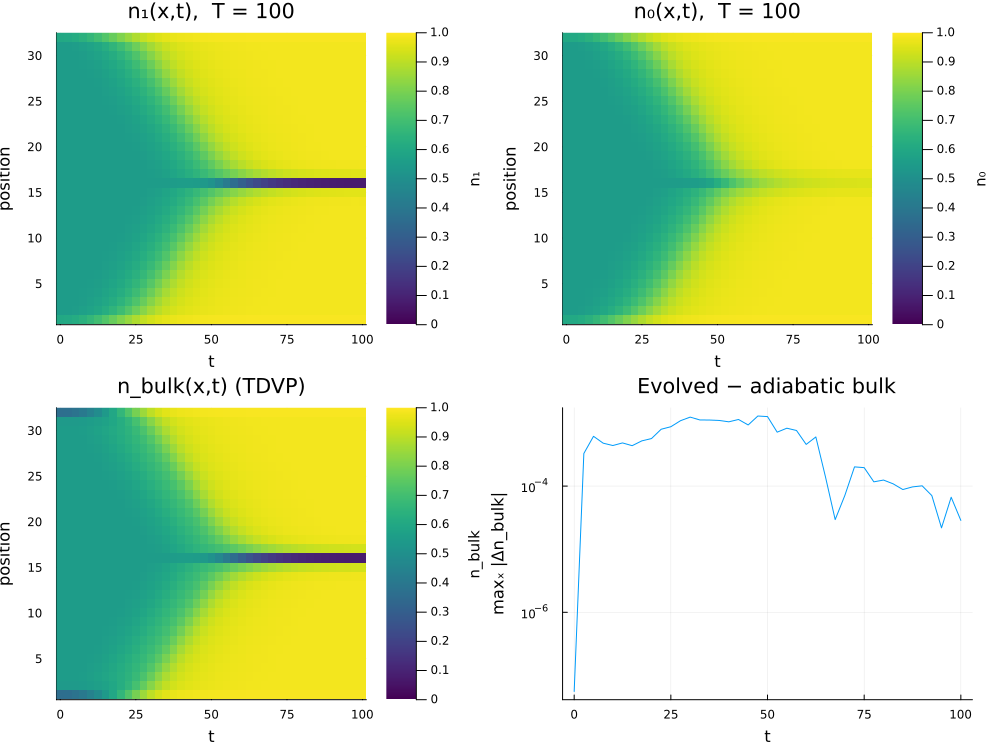

In [36]:
r = full_tdvp
p_n1 = heatmap(r.times, 1:Nt, r.n1; c=:viridis, clims=(0, 1), xlabel="t", ylabel="position",
               colorbar_title="n₁", title="n₁(x,t),  T = $(Int(r.T))")
p_n0 = heatmap(r.times, 1:Nt, r.n0; c=:viridis, clims=(0, 1), xlabel="t", ylabel="position",
               colorbar_title="n₀", title="n₀(x,t),  T = $(Int(r.T))")
p_nb = heatmap(r.times, 1:Nt, r.n_bulk; c=:viridis, clims=(0, 1), xlabel="t", ylabel="position",
               colorbar_title="n_bulk", title="n_bulk(x,t) (TDVP)")
p_d = plot(r.times, vec(maximum(abs, full_tdvp.n_bulk - full_mcw.n_bulk; dims=1)); yscale=:log10,
           xlabel="t", ylabel="maxₓ |Δn_bulk|", label="", title="Evolved − adiabatic bulk")
plot(p_n1, p_n0, p_nb, p_d; layout=(2, 2), size=(1000, 750))